In [1]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [ ]:
path = r"dataset/PetImages"

dataset = datasets.ImageFolder(
    root=path,
    transform=transform
)

In [4]:
print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

Total images: 24998
Classes: ['Cat', 'Dog']
Class mapping: {'Cat': 0, 'Dog': 1}


In [5]:
import os
from PIL import Image

removed = 0

for folder in ["Cat", "Dog"]:
    folder_path = os.path.join(path, folder)

    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)

        try:
            with Image.open(file_path) as img:
                img.verify()

        except Exception:
            os.remove(file_path)
            removed += 1

print("Corrupted images removed:", removed)

C:\Users\Mohammed Murtuza Ali\AppData\Roaming\Python\Python313\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Corrupted images removed: 0


In [7]:
dataset = datasets.ImageFolder(
    root=path,
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)

Total images: 24998
Classes: ['Cat', 'Dog']


In [8]:
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size]
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 19998
Testing images: 5000


In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [10]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])
Labels: tensor([0, 1, 1, 1, 0, 1, 0, 0, 0, 1])


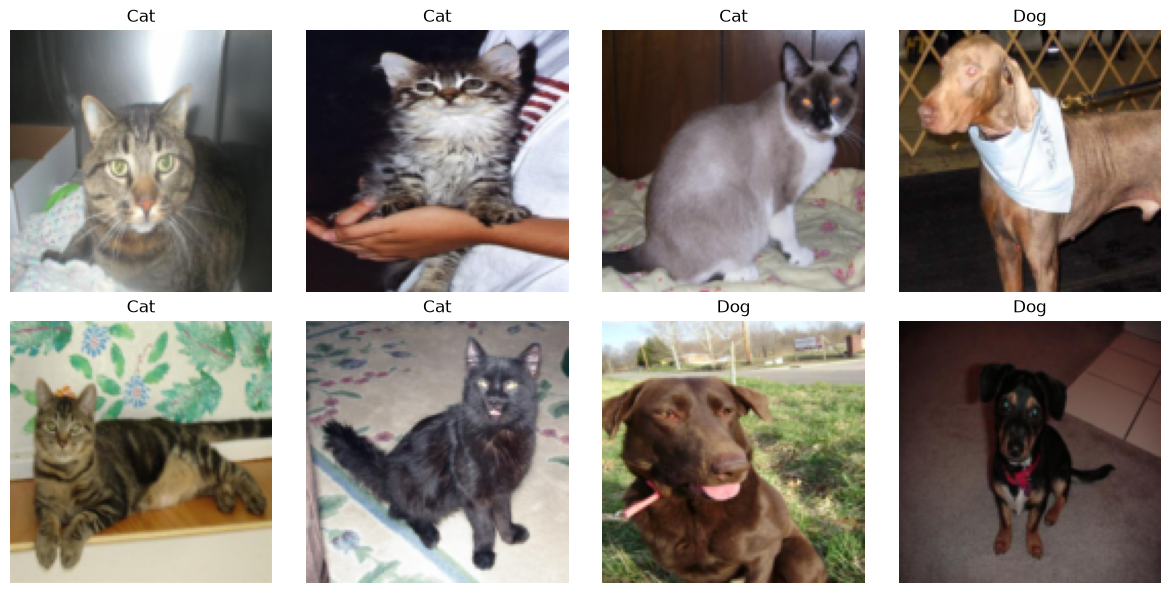

In [11]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0)

    ax.imshow(img)
    ax.set_title(dataset.classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import torch.nn as nn
import torch.nn.functional as F

In [13]:
class CatDogCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(64 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CatDogCNN().to(device)

print("Device:", device)
print(model)

Device: cuda
CatDogCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=65536, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [16]:
epochs = 5

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/5], Loss: 0.6483
Epoch [2/5], Loss: 0.5178
Epoch [3/5], Loss: 0.4319
Epoch [4/5], Loss: 0.3431
Epoch [5/5], Loss: 0.2432


In [17]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 76.72%


In [ ]:
from PIL import Image

image_path = r"dataset/PetImages"

img = Image.open(image_path).convert("RGB")

img_tensor = transform(img).unsqueeze(0).to(device)

In [21]:
model.eval()

with torch.no_grad():
    output = model(img_tensor)
    prediction = torch.argmax(output, dim=1).item()

class_names = dataset.classes

print("Prediction:", class_names[prediction])

Prediction: Dog


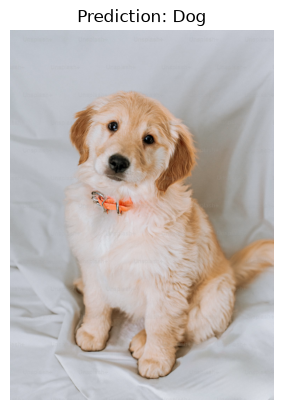

In [22]:
plt.imshow(img)
plt.title(f"Prediction: {class_names[prediction]}")
plt.axis("off")
plt.show()

In [23]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

In [24]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
))

              precision    recall  f1-score   support

         Cat       0.74      0.82      0.78      2494
         Dog       0.80      0.71      0.75      2506

    accuracy                           0.77      5000
   macro avg       0.77      0.77      0.77      5000
weighted avg       0.77      0.77      0.77      5000



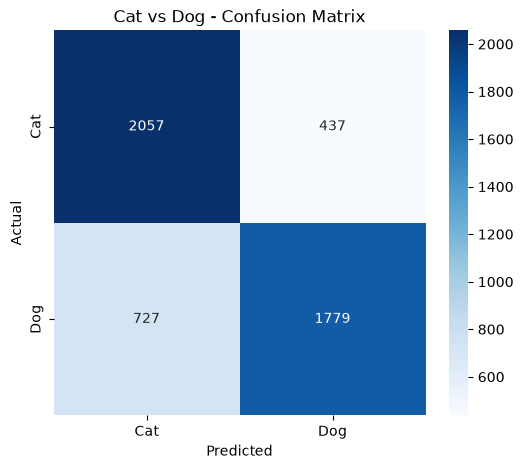

In [25]:
import seaborn as sns

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cat vs Dog - Confusion Matrix")
plt.show()

In [26]:
import os

os.makedirs("saved_model", exist_ok=True)

torch.save(model.state_dict(), "saved_model/cat_dog_cnn.pth")

print("Model saved successfully!")

Model saved successfully!


In [27]:
print(os.path.exists("saved_model/cat_dog_cnn.pth"))

True
